# B15 怎样预测未来一周用电量并滚动评价？

用标明机制的模拟每日用电量，训练同时输出未来 7 天的随机森林。分开区间校准窗口与最终回测窗口，比较同星期基线和直接多步预测。

先修：B06、B07、B10；多输出回归、滚动起点、经验预测区间。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 模拟日历与负荷机制
日用电由周节律、季节、缓慢趋势及噪声组成。单位 kWh 是教学单位，数据不代表实际城市。多步预测时不能把未来真实用电填进滞后特征。

In [2]:
import numpy as np,pandas as pd,json
from sklearn.ensemble import RandomForestRegressor
rng=np.random.default_rng(15); dates=pd.date_range('2022-01-01',periods=740,freq='D'); t=np.arange(len(dates))
energy=120+18*np.sin(2*np.pi*t/365)+20*(dates.dayofweek.to_numpy()<5)+0.025*t+rng.normal(0,7,len(t))
series=pd.Series(energy,index=dates,name='kwh')
frame=pd.DataFrame({'weekday':dates.dayofweek,'annual_sin':np.sin(2*np.pi*t/365),'annual_cos':np.cos(2*np.pi*t/365)},index=dates)
for lag in range(14): frame[f'lag_{lag}']=series.shift(lag)
features=list(frame.columns)
for horizon in range(1,8): frame[f'y_{horizon}']=series.shift(-horizon)
targets=[f'y_{h}' for h in range(1,8)]
series.to_csv(DATA_DIR/'simulated_daily_energy.csv',index_label='date')


## 2. 每个预测起点只训练已经获得完整标签的行
若今天索引为 origin，训练行的未来第 7 天必须不晚于今天。因此只取到 origin−7。森林一次输出 7 个数，直接多步预测避免递归把自己的误差再喂回去。

In [3]:
def forecast_at(origin):
    history=frame.iloc[:origin-6].dropna(subset=features+targets)
    assert history.index[-1]+pd.Timedelta(days=7)<=dates[origin]
    estimator=RandomForestRegressor(n_estimators=40,max_depth=8,min_samples_leaf=3,random_state=15,n_jobs=1)
    estimator.fit(history[features],history[targets])
    prediction=estimator.predict(frame.iloc[[origin]][features])[0]
    baseline=series.iloc[origin-6:origin+1].to_numpy()
    actual=series.iloc[origin+1:origin+8].to_numpy()
    return prediction,baseline,actual
calibration_origins=[390,420,450]
test_origins=[510,540,570,600,630,660,690,720]


## 3. 区间只用早期回测误差校准
用早期窗口绝对误差的 90% 分位数扩展点预测。这是时序经验区间，没有直接套用独立同分布 conformal 保证。校准后固定宽度，在更晚窗口检查覆盖与误差。

In [4]:
calibration_errors=[]
for origin in calibration_origins:
    pred,base,actual=forecast_at(origin)
    calibration_errors.extend(abs(actual-pred))
width=float(np.quantile(calibration_errors,0.9,method='higher'))
rows=[]
for origin in test_origins:
    pred,base,actual=forecast_at(origin)
    for h in range(7):
        rows.append({'origin':dates[origin],'date':dates[origin+h+1],'horizon':h+1,'actual':actual[h],'forest':pred[h],'seasonal':base[h],'lower':pred[h]-width,'upper':pred[h]+width})
result=pd.DataFrame(rows)


## 4. 按预测距离检查，而非混成一个漂亮数字
分别报告第 1—7 天误差，整体 MAE、区间覆盖和宽度。测试窗口从未用于调宽度；覆盖不足是需要报告的结果，不能看完测试再把区间加宽。

In [5]:
result['absolute_error']=abs(result['actual']-result['forest'])
coverage=float(((result['actual']>=result['lower'])&(result['actual']<=result['upper'])).mean())
metrics={'forecast_windows':len(test_origins),'forest_mae':float(result['absolute_error'].mean()),'seasonal_mae':float(abs(result['actual']-result['seasonal']).mean()),'empirical_coverage':coverage,'interval_width':2*width,'nominal_target':0.9,'iid_guarantee_claimed':False}
result.to_csv(OUT_DIR/'rolling_predictions.csv',index=False)
result.groupby('horizon')['absolute_error'].mean().to_csv(OUT_DIR/'horizon_mae.csv')
(OUT_DIR/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
last=result.tail(7); plt.plot(last['date'],last['actual'],'o-',label='实际'); plt.plot(last['date'],last['forest'],'o-',label='森林'); plt.plot(last['date'],last['seasonal'],'--',label='同星期基线'); plt.fill_between(last['date'],last['lower'],last['upper'],alpha=0.2)
plt.ylabel('每日用电 / kWh'); plt.xticks(rotation=25); plt.legend(); plt.tight_layout(); plt.savefig(OUT_DIR/'weekly_forecast.png'); plt.close(); print(metrics)


{'forecast_windows': 8, 'forest_mae': 6.138293515018776, 'seasonal_mae': 6.8722398243423095, 'empirical_coverage': 0.9642857142857143, 'interval_width': 30.10406630928395, 'nominal_target': 0.9, 'iid_guarantee_claimed': False}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

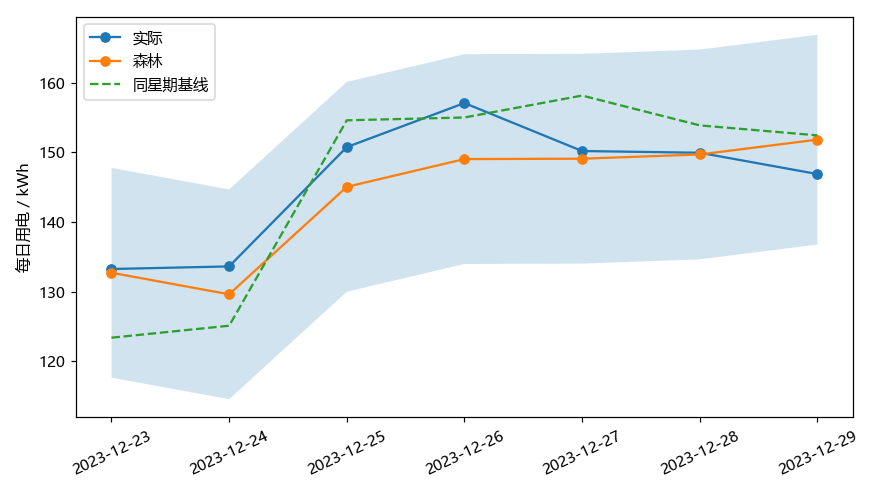

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
数据是模拟用电，不能把模型分数当真实能源预测成绩。校准残差有时间相关性，这里的区间只是经验评估；预训练候选另见拓展。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。